# APRAU — Group 26 | End-to-end Machine Learning Project
**Students:** 1131504 · 1250515 · 1220638  
**Dataset:** `dataset_grupo_26.csv`  
**Repository:** https://github.com/LadyCiaradh/APRAU_1131504_1250515_1220638

This is a **worked learning notebook**, not a claim that every section is compulsory for Part 1. Confirm the detailed assignment on Moodle. Run cells from top to bottom and write your own interpretations of the outputs.

## 0. Environment
In a terminal from the repository root:
```bash
python -m venv .venv
# Windows PowerShell: .venv\Scripts\Activate.ps1
# macOS/Linux: source .venv/bin/activate
python -m pip install -r requirements.txt
jupyter lab
```
Select the `.venv` Python kernel. Keep the dataset in `data/dataset_grupo_26.csv`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.model_selection import train_test_split, KFold, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.linear_model import LinearRegression, Ridge, Lasso, LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
                             accuracy_score, balanced_accuracy_score, f1_score,
                             classification_report, ConfusionMatrixDisplay, confusion_matrix)
RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
print('Ready! pandas:', pd.__version__)

Ready! pandas: 3.1.0


## 1. Load and inspect data
**Why:** establish shape, data types, class balance, missing values, duplicates, and suspicious variables before modeling.

In [3]:
paths = [Path('../data/dataset_grupo_26.csv'), Path('dataset_grupo_26.csv'), Path('/mnt/data/dataset_grupo_26.csv')]
path = next((p for p in paths if p.exists()), None)
if path is None:
    raise FileNotFoundError('Place dataset_grupo_26.csv in the data/ folder')
df = pd.read_csv(path)
print('Shape:', df.shape)
display(df.head(), df.describe(include='all').T)
print('Missing values:', df.isna().sum().sum())
print('Duplicates:', df.duplicated().sum())
print('Constant columns:', df.columns[df.nunique(dropna=False) <= 1].tolist())
print('Classes:')
display(df['target_class'].value_counts().to_frame('count'))

Shape: (2000, 35)


,age_level,gender,bmi_level,smoking,age,age_normalized,bmi,HbA1c_level,cholesterol,sleep_hours,...,hdl,ldl,education_level,employment_status,systolic_index,calcium_baseline,plasma_value,ldl_alternative,target_regression,target_class
0,Senior,Female,Overweight,Never,72,0.804598,29.274836,6.902539,230.000000,4.085643,...,64.012168,129.853982,Primary,Retired,136.462389,9.42,1.108329,120.000000,127.0,DI_HY
1,Senior,Female,Obese,Never,79,0.885057,40.580000,7.500000,231.016529,7.024838,...,64.396985,129.687884,Primary,Employed,134.061418,9.42,1.279992,110.000000,200.0,DI
2,Senior,Female,Normal,Former,89,1.000000,20.400000,6.970370,231.000000,7.700000,...,45.000000,149.000000,Secondary,Employed,112.000000,9.42,1.018947,131.000000,147.0,DI_HY
3,Middle,Female,Normal,Current,37,0.402298,19.600000,6.900000,199.000000,8.000000,...,79.000000,111.000000,Secondary,Unemployed,138.000000,9.42,1.375706,129.371366,158.0,DI_HY
4,Middle,Male,Underweight,Current,24,0.252873,18.300000,6.000000,233.000000,7.000000,...,85.000000,102.000000,Secondary,Unemployed,103.000000,9.42,1.309218,174.000000,163.0,DI


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age_level,2000,4,Mature,670,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,2000,2,Male,1006,NaN,NaN,NaN,NaN,NaN,NaN,NaN
bmi_level,2000,4,Obese,811,NaN,NaN,NaN,NaN,NaN,NaN,NaN
smoking,2000,3,Never,718,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,2000.0,NaN,NaN,NaN,53.681,20.138546,14.0,37.0,54.0,71.0,89.0
age_normalized,2000.0,NaN,NaN,NaN,0.594034,0.231477,0.137931,0.402298,0.597701,0.793103,1.0
bmi,2000.0,NaN,NaN,NaN,27.890906,7.428519,15.0,21.6,27.6,34.1,66.36
HbA1c_level,2000.0,NaN,NaN,NaN,6.885149,0.499008,3.5,6.823744,6.924324,7.009524,9.0
cholesterol,2000.0,NaN,NaN,NaN,224.64906,40.912527,150.0,191.0,224.619921,259.0,299.0
sleep_hours,2000.0,NaN,NaN,NaN,6.966857,1.633684,4.0,5.6,6.984778,8.3,10.0


Missing values: 0
Duplicates: 0
Constant columns: ['calcium_baseline']
Classes:


,count
target_class,
DI_HY,1287
DI,644
HT_HY,69


### Interpretation prompts
- What is the meaning and unit of `target_regression`? **Verify with the assignment/data dictionary; do not invent it.**
- What do `DI`, `DI_HY`, and `HT_HY` mean? Verify the official definitions.
- Are there repeated or derived columns? `age_normalized` is derived from age; `systolic_index` appears related to `systolic_bp`. Avoid assuming they provide independent information.
- `calcium_baseline` is constant and therefore not informative.
- `target_regression` and `target_class` must **never** predict each other unless the assignment explicitly establishes that this is valid and not target leakage.

## 2. Exploratory Data Analysis (EDA)

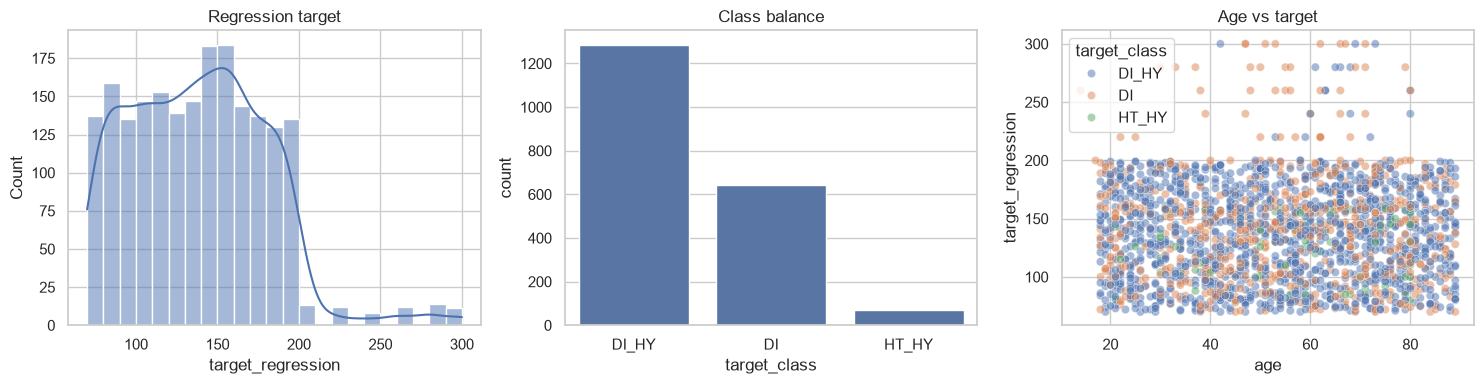

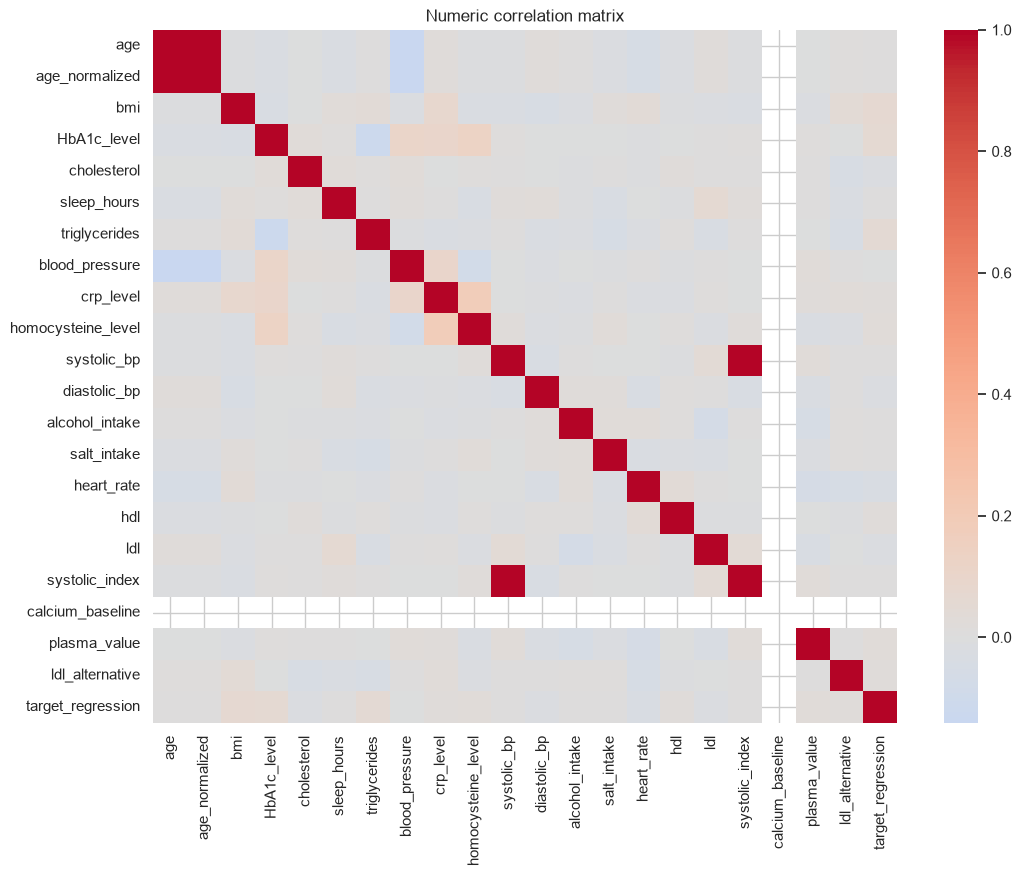

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(df['target_regression'], kde=True, ax=axes[0]); axes[0].set_title('Regression target')
sns.countplot(data=df, x='target_class', order=df['target_class'].value_counts().index, ax=axes[1]); axes[1].set_title('Class balance')
sns.scatterplot(data=df, x='age', y='target_regression', hue='target_class', alpha=.5, ax=axes[2]); axes[2].set_title('Age vs target')
plt.tight_layout(); plt.show()
num = df.select_dtypes(include='number')
plt.figure(figsize=(12, 9)); sns.heatmap(num.corr(), cmap='coolwarm', center=0); plt.title('Numeric correlation matrix'); plt.show()

## 3. Data splitting and preprocessing
**Important:** split before fitting imputers, encoders, or scalers. All preprocessing is inside scikit-learn pipelines, so cross-validation never learns from validation folds. We remove the opposite target, the constant column, and two clearly redundant representations. Further leakage checks are your responsibility.

In [5]:
DROP_COMMON = ['calcium_baseline', 'age_normalized', 'systolic_index']
def features_for(target):
    other = 'target_class' if target == 'target_regression' else 'target_regression'
    X = df.drop(columns=[target, other] + DROP_COMMON)
    y = df[target]
    return X, y

def make_preprocessor(X):
    numeric = X.select_dtypes(include=np.number).columns.tolist()
    categorical = X.select_dtypes(exclude=np.number).columns.tolist()
    return ColumnTransformer([
        ('numeric', Pipeline([('impute', SimpleImputer(strategy='median')),
                              ('scale', StandardScaler())]), numeric),
        ('categorical', Pipeline([('impute', SimpleImputer(strategy='most_frequent')),
                                  ('encode', OneHotEncoder(handle_unknown='ignore'))]), categorical)
    ])
Xr, yr = features_for('target_regression')
Xr_train, Xr_test, yr_train, yr_test = train_test_split(Xr, yr, test_size=.2, random_state=RANDOM_STATE)
Xc, yc = features_for('target_class')
Xc_train, Xc_test, yc_train, yc_test = train_test_split(Xc, yc, test_size=.2, random_state=RANDOM_STATE, stratify=yc)
print('Regression train/test:', Xr_train.shape, Xr_test.shape)
print('Classification train/test:', Xc_train.shape, Xc_test.shape)

Regression train/test: (1600, 30) (400, 30)
Classification train/test: (1600, 30) (400, 30)


## 4. Regression: baseline, Linear Regression, Ridge, Lasso
Compare against a mean-predicting baseline. Use 5-fold CV **on training data only** to select models; then evaluate the chosen models once on held-out test data.

In [6]:
reg_models = {
    'Dummy mean': DummyRegressor(strategy='mean'),
    'Linear regression': LinearRegression(),
    'Ridge': Ridge(alpha=1.0),
    'Lasso': Lasso(alpha=1.0, max_iter=20000)
}
reg_cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
reg_rows = []
for name, estimator in reg_models.items():
    pipe = Pipeline([('preprocess', make_preprocessor(Xr_train)), ('model', estimator)])
    scores = cross_validate(pipe, Xr_train, yr_train, cv=reg_cv,
                            scoring={'rmse': 'neg_root_mean_squared_error', 'r2': 'r2'}, n_jobs=-1)
    reg_rows.append({'model': name, 'CV RMSE': -scores['test_rmse'].mean(), 'CV R2': scores['test_r2'].mean()})
reg_results = pd.DataFrame(reg_rows).sort_values('CV RMSE')
display(reg_results)

,model,CV RMSE,CV R2
0,Dummy mean,41.415540,-0.001361
3,Lasso,41.422144,-0.001802
2,Ridge,41.834979,-0.022152
1,Linear regression,41.839388,-0.022368


## 5. Hyperparameter tuning for regularization
Ridge and Lasso penalize coefficients; tuning `alpha` inside CV helps control overfitting. Smaller RMSE is better.

In [7]:
alphas = np.logspace(-3, 3, 15)
reg_tuned = {}
for name, estimator in [('Ridge', Ridge()), ('Lasso', Lasso(max_iter=30000))]:
    search = GridSearchCV(Pipeline([('preprocess', make_preprocessor(Xr_train)), ('model', estimator)]),
                          {'model__alpha': alphas}, scoring='neg_root_mean_squared_error',
                          cv=reg_cv, n_jobs=-1)
    search.fit(Xr_train, yr_train)
    reg_tuned[name] = search.best_estimator_
    print(name, 'best alpha:', search.best_params_['model__alpha'], 'CV RMSE:', -search.best_score_)

Ridge best alpha: 1000.0 CV RMSE: 41.416553185156545
Lasso best alpha: 2.6826957952797246 CV RMSE: 41.41077147790093


## 6. Final regression test evaluation
Test metrics must not be used to keep changing model choices. Report MAE, RMSE, and R² and inspect residuals.

,model,MAE,RMSE,R2
1,Linear regression,37.406210,45.500940,0.018270
2,Ridge,37.249627,45.539920,0.016587
3,Lasso,37.436245,45.911498,0.000473
0,Dummy mean,37.438934,45.928002,-0.000246


CV-best among untuned models: Dummy mean


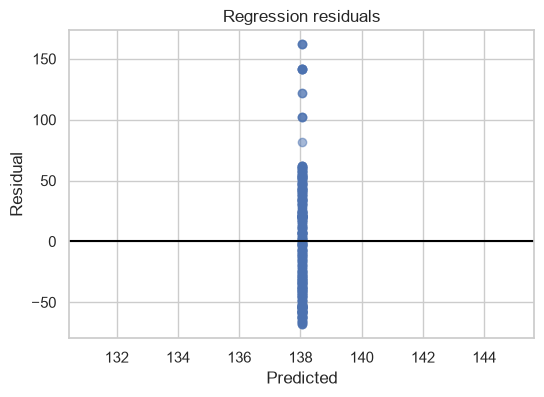

In [8]:
reg_final = {'Dummy mean': Pipeline([('preprocess', make_preprocessor(Xr_train)), ('model', DummyRegressor())]),
             'Linear regression': Pipeline([('preprocess', make_preprocessor(Xr_train)), ('model', LinearRegression())]),
             **reg_tuned}
reg_test_rows = []
for name, model in reg_final.items():
    model.fit(Xr_train, yr_train)
    pred = model.predict(Xr_test)
    reg_test_rows.append({'model': name, 'MAE': mean_absolute_error(yr_test, pred),
                          'RMSE': np.sqrt(mean_squared_error(yr_test, pred)), 'R2': r2_score(yr_test, pred)})
display(pd.DataFrame(reg_test_rows).sort_values('RMSE'))
selected_name = reg_results.iloc[0]['model']
print('CV-best among untuned models:', selected_name)
chosen = reg_final[selected_name]
pred = chosen.predict(Xr_test)
fig, ax = plt.subplots(figsize=(6,4)); ax.scatter(pred, yr_test-pred, alpha=.5); ax.axhline(0, color='black'); ax.set(xlabel='Predicted', ylabel='Residual', title='Regression residuals'); plt.show()

## 7. Classification: baseline, Logistic Regression and LDA
The target has **three classes**, including a minority class. Ordinary accuracy can hide poor minority-class results. Use stratified 5-fold CV and **macro-F1** as the main selection metric; also report balanced accuracy.

In [9]:
clf_models = {'Most frequent baseline': DummyClassifier(strategy='most_frequent'),
              'Logistic regression': LogisticRegression(max_iter=3000, class_weight='balanced'),
              'LDA': LinearDiscriminantAnalysis()}
clf_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
clf_rows = []
for name, estimator in clf_models.items():
    pipe = Pipeline([('preprocess', make_preprocessor(Xc_train)), ('model', estimator)])
    scores = cross_validate(pipe, Xc_train, yc_train, cv=clf_cv,
                            scoring={'f1_macro':'f1_macro','balanced_accuracy':'balanced_accuracy','accuracy':'accuracy'}, n_jobs=-1)
    clf_rows.append({'model':name, 'CV macro-F1':scores['test_f1_macro'].mean(),
                     'CV balanced accuracy':scores['test_balanced_accuracy'].mean(),
                     'CV accuracy':scores['test_accuracy'].mean()})
clf_results = pd.DataFrame(clf_rows).sort_values('CV macro-F1', ascending=False)
display(clf_results)

,model,CV macro-F1,CV balanced accuracy,CV accuracy
2,LDA,0.547561,0.589497,0.655000
1,Logistic regression,0.531725,0.592321,0.525625
0,Most frequent baseline,0.261090,0.333333,0.643750


## 8. Tune Logistic Regression on training folds only

In [10]:
clf_search = GridSearchCV(
    Pipeline([('preprocess', make_preprocessor(Xc_train)),
              ('model', LogisticRegression(max_iter=3000, class_weight='balanced'))]),
    {'model__C': [0.01, 0.1, 1, 10, 100]}, cv=clf_cv, scoring='f1_macro', n_jobs=-1)
clf_search.fit(Xc_train, yc_train)
print('Best C:', clf_search.best_params_, 'CV macro-F1:', clf_search.best_score_)

Best C: {'model__C': 1} CV macro-F1: 0.5317247273991674


## 9. Final classification test evaluation
Choose the model using cross-validation, not the test set. Inspect per-class precision/recall/F1 and the confusion matrix.

Selected: LDA
Test accuracy: 0.6625
Test balanced accuracy: 0.5977818569891685
Test macro-F1: 0.5242796333877928
              precision    recall  f1-score   support

          DI       0.45      0.04      0.07       129
       DI_HY       0.67      0.97      0.79       257
       HT_HY       0.65      0.79      0.71        14

    accuracy                           0.66       400
   macro avg       0.59      0.60      0.52       400
weighted avg       0.60      0.66      0.56       400



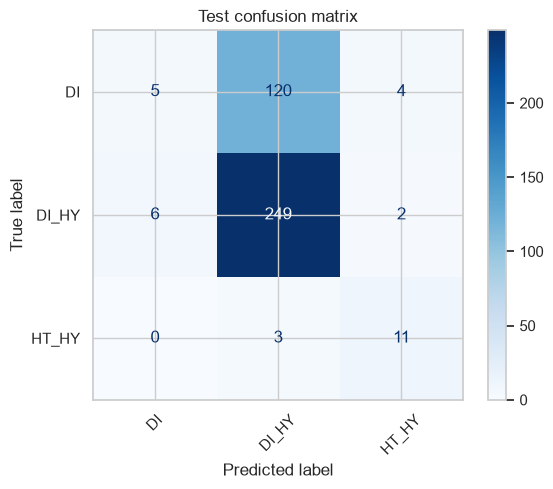

In [11]:
best_untuned_name = clf_results.iloc[0]['model']
if clf_search.best_score_ >= clf_results.iloc[0]['CV macro-F1']:
    best_clf_name = 'Tuned logistic regression'
    best_clf = clf_search.best_estimator_
else:
    best_clf_name = best_untuned_name
    best_clf = Pipeline([('preprocess', make_preprocessor(Xc_train)),
                         ('model', clf_models[best_untuned_name])])
best_clf.fit(Xc_train, yc_train)
yc_pred = best_clf.predict(Xc_test)
print('Selected:', best_clf_name)
print('Test accuracy:', accuracy_score(yc_test, yc_pred))
print('Test balanced accuracy:', balanced_accuracy_score(yc_test, yc_pred))
print('Test macro-F1:', f1_score(yc_test, yc_pred, average='macro'))
print(classification_report(yc_test, yc_pred, zero_division=0))
ConfusionMatrixDisplay.from_predictions(yc_test, yc_pred, xticks_rotation=45, cmap='Blues'); plt.title('Test confusion matrix'); plt.show()

## 10. Conclusions — complete after running the notebook
Write 1–2 paragraphs per question:
1. What does the dataset contain, and what does each target mean according to the official specification?
2. Which predictors have the strongest visible relationships with the targets? Are any redundant or suspicious?
3. Did Ridge/Lasso improve regression compared with Linear Regression and the dummy baseline?
4. Which classifier had the highest cross-validated macro-F1? What happened to the rare `HT_HY` class?
5. What are the final held-out test results? Do not claim clinical validity.
6. What are the limitations (class imbalance, synthetic/unknown provenance, potential leakage, sample size, data quality)?
7. Which improvements would you test **in future work**, without reusing the test set for tuning?

### Suggested references
- James et al., *An Introduction to Statistical Learning* (2023).
- APRAU lecture notes: Linear Regression; Classification; Evaluation & Resampling; Ridge/Lasso.
- scikit-learn documentation: pipelines, cross-validation, metrics, linear models.

**Academic integrity:** explain decisions in your own words, preserve reproducibility, and verify Part 1/Part 2 scope in Moodle.